In [1]:
# Import required libraries

import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Set the dataset folder path

dataset_path = "../data/raw/NEU-DET"

# Set training and validation image paths

train_images = dataset_path + "/train/Images"
val_images = dataset_path + "/validation/Images"

print("Training path exists:", os.path.exists(train_images))
print("Validation path exists:", os.path.exists(val_images))

Training path exists: True
Validation path exists: True


In [3]:
# Set the image size

image_size = 224

# Define all defect classes

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Image Size:", image_size)
print("Total Classes:", len(classes))
print("Classes:", classes)

Image Size: 224
Total Classes: 6
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [4]:
# Create empty lists to store images and labels

X_train = []
y_train = []

# Read images from each defect folder

for class_name in classes:

    class_path = os.path.join(train_images, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        # Open the image
        img = Image.open(image_path)

        # Convert image into RGB format
        img = img.convert("RGB")

        # Resize the image
        img = img.resize((image_size, image_size))

        # Convert image into array
        img_array = np.array(img)

        # Store image and its class label
        X_train.append(img_array)
        y_train.append(classes.index(class_name))

print("Training images loaded successfully!")
print("Total images:", len(X_train))
print("Total labels:", len(y_train))

Training images loaded successfully!
Total images: 1440
Total labels: 1440


In [5]:
import os

print("Current location:", os.getcwd())
print("Dataset folder exists:", os.path.exists("../data/raw/NEU-DET"))

Current location: C:\Users\salun\NEU_Surface_Defect_Detection\notebooks
Dataset folder exists: True


In [6]:
import os

dataset_path = "../data/raw/NEU-DET"

print("Dataset exists:", os.path.exists(dataset_path))
print("Folders:", os.listdir(dataset_path) if os.path.exists(dataset_path) else "Path not found")

Dataset exists: True
Folders: ['train', 'validation']


In [7]:
import os

print("Training folders:")
print(os.listdir(train_images))

Training folders:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [8]:
# Create empty lists for validation images and labels

X_val = []
y_val = []

# Read validation images from each class folder

for class_name in classes:

    class_path = os.path.join(val_images, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        # Open image
        img = Image.open(image_path)

        # Convert image into RGB
        img = img.convert("RGB")

        # Resize image
        img = img.resize((image_size, image_size))

        # Convert image into array
        img_array = np.array(img)

        # Store image and label
        X_val.append(img_array)
        y_val.append(classes.index(class_name))

print("Validation images loaded successfully!")
print("Total validation images:", len(X_val))
print("Total validation labels:", len(y_val))

Validation images loaded successfully!
Total validation images: 360
Total validation labels: 360


In [9]:
# Convert training lists into NumPy arrays

X_train = np.array(X_train)
y_train = np.array(y_train)

# Convert validation lists into NumPy arrays

X_val = np.array(X_val)
y_val = np.array(y_val)

# Check dataset shapes

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_train shape: (1440, 224, 224, 3)
y_train shape: (1440,)
X_val shape: (360, 224, 224, 3)
y_val shape: (360,)


In [10]:
# Normalize training images

X_train = X_train / 255.0

# Normalize validation images

X_val = X_val / 255.0

print("Image normalization completed!")

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Image normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


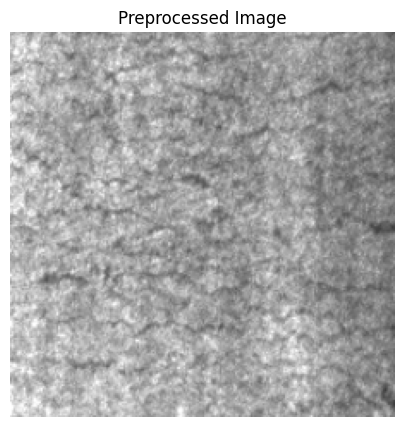

Class Label: 0
Class Name: crazing


In [11]:
# Display one preprocessed image

plt.figure(figsize=(5, 5))

plt.imshow(X_train[0])

plt.title("Preprocessed Image")

plt.axis("off")

plt.show()

# Display its class label

print("Class Label:", y_train[0])
print("Class Name:", classes[y_train[0]])

In [1]:
import os

folders = ["data", "models"]

for folder in folders:
    total_size = 0

    for root, dirs, files in os.walk("../" + folder):
        for file in files:
            path = os.path.join(root, file)
            total_size += os.path.getsize(path)

    size_mb = total_size / (1024 * 1024)

    print(folder, "Size:", round(size_mb, 2), "MB")

data Size: 26.9 MB
models Size: 383.27 MB


In [2]:
import os

for file in os.listdir("../models"):
    path = os.path.join("../models", file)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024 * 1024)

        print(file, ":", round(size, 2), "MB")

baseline_cnn.keras : 127.87 MB
resnet50_fine_tuned.keras : 161.77 MB
resnet50_transfer_learning.keras : 93.62 MB
